In [1]:
import math
from typing import cast

import pandas as pd
import torch

from safetensors.torch import load_file
from scipy.stats import hypergeom
from syntheticpatterns import load_pattern_csv, show_grid
from torch import Tensor, nn
from torch.utils.data import DataLoader

from models.ViT_PSA_CNN_model import ViT_PSA_CNN
from training.training_PSA_CNN import accuracy_fn_binary, load_patterns_codebook, model_train_PSA_CNN
from training.vit_mask_training import model_train_vit
from utils.utils import (
            Calculate_nodes_links,
            Clean_patterns,
            Create_Network_Graph,
            create_dataloaders,
            save_model,
            show_attention,
            )


# Note: 
# This workflow was primarily developed and tested on an NVIDIA CUDA GPU with over 28 GB of free VRAM, using CUDA 13.3 and NVIDIA Studio driver 610.88. 
# As the pipeline relies on CUDA-specific optimizations, device agnostic code has been hardcoded to use a CUDA device. 
# Performance and compatibility may vary on older GPU architectures, drivers, or CUDA versions. 
# If your available VRAM is lower than 28 GB, the pipeline may still run by using lower batch sizes.

The very first step of pre-training involves training a ViTB that was purposely stripped of its positional encodings. The idea was to encourage the network to learn semantic relationships among image patches without relying on their spatial positions. This should help the downstream permutation decoder select, for each class, the most informative patches and reorder them independently of their original positions. 

Because we are using a toy dataset with relatively easy-to-learn visual features, the ViT typically reaches a near perfect test (validation) accuracy within only a few training epochs. A sudden jump in test accuracy between training steps may occur and are not necessarily unexpected in this setting. During evaluation, the same fixed sequence of unmasked (unperturbed) patches is used as input, whereas during training, patches are randomly dropped (with an increasing masking rate over epochs). **We also keep around 10% of the batches with no masking in addition to another 10% chance of perturbing all patch intensities of a given sample to 1 or 0.1 depending in it's original value.** This should encourage the transformer to learn to recognize highly discriminative features from a small subset of patches and their patterns. Consequently, it may achieve very high accuracy when evaluated on the unmasked input. Even after the model appears to be fully trained after only a few epochs, it is important to continue exposing it to an increasing number of masked patches throughout this phase. This encourages the transformer to learn more general semantic relationships between patches rather than relying on particular patch combinations, which may otherwise contribute to the early high test accuracy. This, in turn, should help the permutation decoder identify strongly class-defining patches to present to the CNN in the next phase. If the test accuracy doesn't improve after a few epochs, try restarting from a different random initialization.

In [ ]:
batch_size=64
dataset_size=10_000

train_loader,test_loader,validation_loader,class_names=create_dataloaders(
                    path="../ML_ENV/SPIN/dataset/",#"./data/",
                    batch_size= batch_size,
                    split=["train","test","val"],
                    number_workers=4,
                    prefetch_factor=6,
                    shuffle=False, # Note: when using a subset of the data, random shuffling is always used
                    pin_memory=True,
                    persistent_workers=True,
                    subset_dataset=dataset_size)

Loading dataset from disk:   0%|          | 0/35 [00:00<?, ?it/s]

Used a subset with 10000 random samples
Used a subset with 2000 random samples
Used a subset with 2000 random samples


In [3]:
loss_fn_vit=nn.BCEWithLogitsLoss()

model_vit_training:nn.Module = ViT_PSA_CNN(
            Patch=4,
            number_of_patches=4096,
            embedding_dimension=768,
            nb_heads=12,
            MLP_Size=3072,
            CNN_features=64,
            mlp_dropout=0.1,
            embedding_dropout=0.1,
            num_transformer_layers=12,
            num_class=1
            )

# tweak only the vit's param:
vit_pretrain_params  = (
        list(model_vit_training.transform_patch.parameters())
        + list(model_vit_training.patch_embedding.parameters())
        + [model_vit_training.class_token]
        + list(model_vit_training.transformer.parameters())
        + list(model_vit_training.classifier.parameters())
    )

optimizer_vit = torch.optim.AdamW(
    params=vit_pretrain_params ,
    betas=(0.9, 0.999), 
    weight_decay=3e-4, 
    lr=1e-4
)

# Epochs:
batches_per_epoch = int(math.ceil((dataset_size/batch_size)))
epochs_vit=23
warmup_vit_epoch=5


# steps
warmup_steps_vit = batches_per_epoch *warmup_vit_epoch  # warmup phase in steps
total_steps_vit  = batches_per_epoch *epochs_vit        # full schedule in step
decay_steps_vit  = total_steps_vit - warmup_steps_vit   # cosine phase in steps

# warmup:
warmup_vit = torch.optim.lr_scheduler.LinearLR(
    optimizer_vit,
    start_factor=1e-4,
    end_factor=1, 
    total_iters=warmup_steps_vit
)

# lr rate:
cosine_vit = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_vit,
    T_max=decay_steps_vit,
    eta_min=1e-6
)

scheduler_vit = torch.optim.lr_scheduler.SequentialLR(
    optimizer_vit,
    schedulers=[warmup_vit, cosine_vit],
    milestones=[warmup_steps_vit]
)

model_vit_training.to("cuda")
#Note: channels_last optimization gives performance benefits for CNNs (second phase) using CUDA devices. However, typically negligible for the Vit pretraining.
model_vit_training=model_vit_training.to(memory_format=torch.channels_last) # type: ignore
model_vit_training=torch.compile(model_vit_training) # type: ignore[assignment]

In [ ]:
model_res=model_train_vit(
    model=model_vit_training,
    epochs=23,
    end_anneal=20,
    optimizer=
    optimizer_vit, 
    loss_fn=loss_fn_vit,
    train_data_loader=cast(DataLoader[dict[str, Tensor]], train_loader),
    test_data_loader=cast(DataLoader[dict[str, Tensor]], test_loader),
    lr_scheduler=scheduler_vit,
    grad_clip=1, 
    mask_anneal=True)

save_model(model=model_vit_training,safe_root="models/weights",model_name="Vit_Pretrained_DEB",compiled=True)

schedule was applied
gradient clipping was applied with a value of 1
using autocast bf16


  0%|          | 0/23 [00:00<?, ?it/s]

applying 50.0% of patch masking
-----------
Batch: 0/157
Batch: 100/157
Batch: 157/157
EPOCH 0 || Train loss 0.5490 | Train acc: 67.48% || Test loss: 0.1049 | Test acc: 98.40% || last sample lr=2.001e-05
----------------------------
applying 50.0% of patch masking
-----------
Batch: 0/157
Batch: 100/157
Batch: 157/157
EPOCH 1 || Train loss 0.1121 | Train acc: 96.65% || Test loss: 0.1225 | Test acc: 95.60% || last sample lr=4.001e-05
----------------------------
Saved ./models/weights/Vit_Pretraining_e1_chpt at models/weights/Vit_Pretraining_e1_chpt.safetensors
#####################
applying 50.0% of patch masking
-----------
Batch: 0/157
Batch: 100/157
Batch: 157/157
EPOCH 2 || Train loss 0.0000 | Train acc: 100.00% || Test loss: 0.2742 | Test acc: 91.55% || last sample lr=6.000e-05
----------------------------
Saved ./models/weights/Vit_Pretraining_e2_chpt at models/weights/Vit_Pretraining_e2_chpt.safetensors
#####################
applying 50.0% of patch masking
-----------
Batch: 0/1

With the ViT backbone now trained to high accuracy, we can bring the permutation decoder and CNN modules into the training loop. The goal is to use the ViT embeddings as input to a bilinear symmetry-head decoder that predicts a permutation matrix which is then applied to the input image to rearrange its patches. The better the decoder places many class-defining patterns within the CNN's visible window, the easier it should be for the CNN to classify the image. The CNN, however, only sees a restricted window of the resulting image. This window gradually shrinks and jitters around the center during training, while remaining fixed during testing. This setup encourages the decoder to place patterns with high class defining features repeatedly within the regions that are most likely to be visible to the CNN.

As our goal is to discover a large number of strongly class-defining patterns, we need a few additional losses alongside the BCE classification loss. We use a diversity loss that discourages the decoder from relying on only a very small number of patterns. This is particularly important for the toy dataset, where a few highly discriminative patterns may otherwise be sufficient to achieve good classification accuracy. We also use an auxiliary loss that measures how far the decoder's predicted patterns are from the corresponding patterns in the original pattern set. During the subsequent cleaning step, each predicted pattern can be replaced by its exact original pattern. This encourages the decoder to learn genuine permutations of existing patterns rather than effectively hallucinating new patterns that were not present in the input data.

>Note: *some ViT checkpoints may perform better than others. If the whole model architecture after training doesn't perform well (eg. overfitting or one class is underperforming), simply using another vit checkpoint or retrain the vit may fix it without changing downstream settings.*

In [2]:
# Full network (ViT + perm decoder + Sinkhorn + CNN) is significantly more memory-hungry and slower per sample than the ViT-only path. 
# Therefore, we're reducing the batch and dataset size
batch_size=18
dataset_size=3000 #800

train_loader,test_loader,validation_loader,class_names=create_dataloaders(
                    path="../ML_ENV/SPIN/dataset/",#"./data/",
                    batch_size= batch_size,
                    split=["train","test","val"],
                    number_workers=4,
                    prefetch_factor=6,
                    shuffle=False, # Note: when using a subset of the data, random shuffling is always used
                    pin_memory=True,
                    persistent_workers=True,
                    subset_dataset=dataset_size)
print(f'using {int(math.ceil((dataset_size/batch_size)))} steps par epoch')

Loading dataset from disk:   0%|          | 0/35 [00:00<?, ?it/s]

Used a subset with 3000 random samples
Used a subset with 600 random samples
Used a subset with 600 random samples
using 167 steps par epoch


In [ ]:
torch.set_float32_matmul_precision('high')
# Note: 
# This optimization uses 'TF32' for float32 precision matmuls on latest CUDA devices which can give a 2x speed up against a minor precision loss.
# Eventhough during traing we will be using autocast with lower precision (bf16), some operations still left in fp32 can still benefit from this optimization.

model_PSA:nn.Module = ViT_PSA_CNN(
            Patch=4,
            number_of_patches=4096,
            embedding_dimension=768,
            nb_heads=12,
            MLP_Size=3072,
            CNN_features=64,
            mlp_dropout=0.1,
            embedding_dropout=0.1,
            num_transformer_layers=12,
            num_class=1
            )
loss_fn=nn.BCEWithLogitsLoss()

# Only load pretrained Vit weights
vit_checkpoint  = load_file("./models/weights/Vit_Pretrained_DEB.safetensors")

keys_to_load = (
    "transform_patch.",
    "patch_embedding.",
    "class_token",
    "transformer.",
    "classifier."
)

# Get weights for each vit param
filtered_checkpoint = {
    k: v for k, v in vit_checkpoint.items()
    if k.startswith(keys_to_load)
}

# load part of the models weight (vit only)
missing, unexpected = model_PSA.load_state_dict(
    filtered_checkpoint,
    strict=False
)

# Check if some weights were not loaded or failed, none of the vit pretrained weights should be missing
print("Missing:", missing)
print("Unexpected:", unexpected)

# Let's configure different learning rates for each architecture phase:

# Phase 1: ViT + classifier (CLS-token pretraining)
# get the trainable params:
vit_params = (
    list(model_PSA.transform_patch.parameters())
    + list(model_PSA.patch_embedding.parameters())
    + [model_PSA.class_token]
    + list(model_PSA.transformer.parameters())
    + list(model_PSA.classifier.parameters())
)

# Phase 2: Decoder, and sinkhorn + attention_cnn
decoder_parm= (
    list(model_PSA.perm_decoder.parameters())
    )
decoder_cnn_params = (
     list(model_PSA.sinkhorn.parameters())
    + list(model_PSA.attnpoolcnn.parameters())
    )


# Now a different lr can be applied to each phase:
# Note: 
# 1e-7 for the pretrained vit, and  1e-3 for both the decoder and cnn worked best so far
# the pretrained vit's weights should optimally not be modified too strongly during training to prevent drift
optimizer = torch.optim.AdamW([
    {"params": vit_params, "lr": 1e-7}, 
    {"params":decoder_parm, "lr":1e-3},
    {"params": decoder_cnn_params, "lr": 1e-3},], 
    betas=(0.9, 0.999), weight_decay=3e-4) #3e-6 


# Scheduler config:
# Here we'll use a warmup, a constant hold, cosine decay, and a new linear at the end 
# Model will be saved after specific thresholds are reached (if test acc>90 and train acc > 80:)

batches = int(math.ceil((dataset_size/batch_size)))

epochs = 35
warmup = 5
hold = 2          # constant LR after warmup
finetune = 2


warmup_steps = batches * warmup
hold_steps = batches * hold
fine_tune_steps = batches * finetune

total_steps = batches * epochs
cosine_steps = total_steps - warmup_steps - hold_steps - fine_tune_steps

# 1. Warmup
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1e-4,
    end_factor=1.0,
    total_iters=warmup_steps,
)

# 2. Hold LR constant
hold_scheduler = torch.optim.lr_scheduler.ConstantLR(
    optimizer,
    factor=1.0,
    total_iters=hold_steps,
)

# 3. Cosine decay
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=cosine_steps,
    eta_min=1e-5,
)

# 4. Final LR finetune
fine_tune_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=1e-2,
    end_factor=1e-3,
    total_iters=fine_tune_steps,
)

scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[
        warmup_scheduler,
        hold_scheduler,
        cosine_scheduler,
        fine_tune_scheduler,
    ],
    milestones=[
        warmup_steps,
        warmup_steps + hold_steps,
        warmup_steps + hold_steps + cosine_steps,
    ],
)

# move to cuda & optimize model graphs
model_PSA.to("cuda")
model_PSA= model_PSA.to(memory_format=torch.channels_last) # type: ignore
model_PSA= cast(nn.Module, torch.compile(model_PSA))

Missing: ['perm_decoder.W', 'perm_decoder.norm.weight', 'perm_decoder.norm.bias', 'perm_decoder.q.0.weight', 'perm_decoder.q.0.bias', 'perm_decoder.q.3.weight', 'perm_decoder.q.3.bias', 'perm_decoder.k.0.weight', 'perm_decoder.k.0.bias', 'perm_decoder.k.2.weight', 'perm_decoder.k.2.bias', 'perm_decoder.k.5.weight', 'perm_decoder.k.5.bias', 'attnpoolcnn.conv1.0.weight', 'attnpoolcnn.conv1.0.bias', 'attnpoolcnn.conv1.1.weight', 'attnpoolcnn.conv1.1.bias', 'attnpoolcnn.conv1.3.weight', 'attnpoolcnn.conv1.3.bias', 'attnpoolcnn.conv1.4.weight', 'attnpoolcnn.conv1.4.bias', 'attnpoolcnn.conv2.0.weight', 'attnpoolcnn.conv2.0.bias', 'attnpoolcnn.conv2.1.weight', 'attnpoolcnn.conv2.1.bias', 'attnpoolcnn.conv2.3.weight', 'attnpoolcnn.conv2.3.bias', 'attnpoolcnn.conv2.4.weight', 'attnpoolcnn.conv2.4.bias', 'attnpoolcnn.attn_score.weight', 'attnpoolcnn.attn_score.bias', 'attnpoolcnn.classifier.weight', 'attnpoolcnn.classifier.bias']
Unexpected: []


In [4]:
# A few checks before starting:
# Verify if every trainable param is in exactly one group, and
# no param appears in two groups (would cause double updates).
# Should both be 0

all_params = set(id(p) for p in model_PSA.parameters())
grouped = set(id(p) for p in vit_params+decoder_parm + decoder_cnn_params) 
missing = all_params - grouped
print(f"Missing from phase 2 groups: {len(missing)}")
for name, p in model_PSA.named_parameters():
    if id(p) in missing:
        print(f"  MISSING: {name}")

overlap = set(id(p) for p in vit_params) & set(id(p) for p in decoder_cnn_params)
print(f"Parameters in both groups: {len(overlap)}")

Missing from phase 2 groups: 0
Parameters in both groups: 0


In [ ]:
# Checkpoints are auto-saved by default when trest_acc > 90 AND train_acc > 80.
# We're annealing to reduce the CNN's window size and add random jitter to its possition, in addition there's a 25% chance of puting a 18-22 window size each batch instead
# Loss is determined by; BCE, "aux" which is how close the decoder's proposed patterns are to the real patterns, 
# and div (=diversity) which encourages the model to output more patterns instead of settling for only a few
# Test conditions are fixed with a window size of 18, 0 jitter  
model_res=model_train_PSA_CNN(model=model_PSA,
                              epochs=35,
                              end_anneal=10,
                              optimizer=optimizer,
                              loss_fn=loss_fn,
                              train_data_loader=cast(torch.utils.data.DataLoader[dict[str,torch.Tensor]],train_loader),
                              test_data_loader=cast(torch.utils.data.DataLoader[dict[str,torch.Tensor]], test_loader),
                              lr_scheduler=scheduler,
                              grad_clip=5,
                              aux=1,
                              div=1,
                              BCE=0.5
                                )

schedule was applied
gradient clipping was applied with a value of 5
using autocast bf16


  0%|          | 0/35 [00:00<?, ?it/s]

applying: window_size=24,jitter:0
-----------
Batch: 0/167
Batch: 100/167
Batch: 167/167
EPOCH 0 || last sample lr=2.001e-04
Train loss:1.2445 | Train BCE:0.4539 | Train div.: 0.9963 | Train aux: 0.0212 | Train acc: 73.70% 
Test loss: 1.0992 | Test BCE: 0.0703 | Test div.:  0.9758 | Test aux:  0.0883 | Test acc:  100.00%
----------------------------
applying: window_size=23,jitter:0
-----------
Batch: 0/167
Batch: 100/167
Batch: 167/167
EPOCH 1 || last sample lr=4.001e-04
Train loss:0.9102 | Train BCE:0.0506 | Train div.: 0.8751 | Train aux: 0.0099 | Train acc: 99.80% 
Test loss: 2.3500 | Test BCE: 2.6470 | Test div.:  0.9975 | Test aux:  0.0289 | Test acc:  57.50%
----------------------------
applying: window_size=22,jitter:1
-----------
Batch: 0/167
Batch: 100/167
Batch: 167/167
EPOCH 2 || last sample lr=6.000e-04
Train loss:0.8985 | Train BCE:0.0694 | Train div.: 0.8583 | Train aux: 0.0055 | Train acc: 98.80% 
Test loss: 1.0481 | Test BCE: 0.0496 | Test div.:  0.9961 | Test aux:  0.

Auxiliary loss defines how far a part a given pattern is from their most similar original among our 4096 patterns, this encourages the model to permute, rather than creating new patterns. Diversity loss calculates how much of the patterns are repeated. Note that the test window is typically larger than the training window. As a result, test losses may be somewhat be worse than training ones. The decoder outputs the entire image size (4096 total possible "patch slots"). However as the window size is annealing in the center, patterns may be less repetitive on average with a smaller window size especially located at the center as this may reduce the diversity loss. Similarly, predicted permutations that don't result in intensities like the original patterns may be repeated more often in a larger window, may therefore also increase aux loss. Therefore, it may be preferable to choose checkpoints close to, or after the annealed window size has reached the size of the test window. Additionally, repetition may not be distributed uniformly across classes. One class may naturally produce more repetitive patterns than another, and the div loss may not fully capture this class-specific behavior. Therefore, the results should be inspected separately for each class and checkpoints should be avoided where one class shows substantially more pattern repetition (e.g., fewer than 5 distinct patterns).

Finnally, auxiliary loss is tied to how many patterns are found after thresholding that are real patterns (otherwise they'll be dropped out before calculating the losses), the loss can fluctuate each step. While a lower loss usually means an improvment within the same amount of correctly guessed patterns, if the amount of patterns change after a given step, the one loss may be higher than previously even if the model improved overall. 

With the current toy data, the model tends to overfit or incorrectly identify certain patterns as highly class-defining, particularly during the later stages of annealing. The smaller window size towards the end, resulting in fewer patterns being shown to the CNN, may contribute to the observed loss of generalization. As the window becomes smaller, the task becomes easier if patterns are memorized, allowing the model to rely on a few memorized patterns rather than learning the broader spatial relationships. To address this, a 25% chance of selecting a window size between 18 and 22, instead of the annealed size, was introduced while keeping the jitter in place. This should encourage the model to retain the general semantic relationships between patterns that it learned during the earlier stages of training.

Consequently it's important to check the results empirically; the output patterns should be sufficiently distinct from one another. Some repetition is expected and wanted, but avoid checkpoints whose outputs consist predominantly of the same very few patterns. If the outputs after the permuted patches are "cleaned" by replacing them with the nearest patches from the original image (as done later in this notebook), the patterns should ideally survive that transformation, and their initial intensities should somewhat be similar to those of the corresponding patches in the original image. Finally, the outputs should be checked against the ground-truth labels. While some checkpoints may guess the labels perfectly and appear to perform correctly, they may nevertheless be worse than others at predicting the patterns that are actually class-defining.

In [2]:
# Let's load the data, and the model's weights again:
# set high precision
torch.set_float32_matmul_precision('high')

train_loader,test_loader,validation_loader,class_names=create_dataloaders(
                    path="../ML_ENV/SPIN/dataset/",#"./data/",
                    batch_size= 36,
                    split=["train","test","val"],
                    number_workers=4,
                    prefetch_factor=6,
                    shuffle=False,
                    pin_memory=True,
                    persistent_workers=True,
                    subset_dataset=6000) #3000)

Loading dataset from disk:   0%|          | 0/35 [00:00<?, ?it/s]

Used a subset with 6000 random samples
Used a subset with 1200 random samples
Used a subset with 1200 random samples


In [3]:
# reinit the model:
model_PSA=ViT_PSA_CNN(
        Patch=4,
        number_of_patches=4096,
        embedding_dimension=768,
        nb_heads=12,
        MLP_Size=3072,
        CNN_features=64,
        mlp_dropout=0.1,
        embedding_dropout=0.1,
        num_transformer_layers=12,
        num_class=1
        )

# Change the path to the right working checkpoint
model_PSA.load_state_dict(load_file("models/weights/vit_psa_good_weights.safetensors"))

# optimize the model
model_PSA.to("cuda")
model_PSA=model_PSA.to(memory_format=torch.channels_last) # type: ignore
model_PSA=torch.compile(model_PSA)



For this evaluation we first *"clean"* the permuted patch grid before feeding it to the CNN (`cnn_patches`). As during training, patches are replaced by their exact values (positions and intensities) from the original input image. This removes the residual approximation error introduced by the permutation. 

If the model is well trained, most patches should be kept and the CNN should still classify at high accuracy

In [4]:
# Get a single batch from the loader
batch=cast(dict[str,Tensor], next(iter(test_loader)))
x_im=batch["image"]
x_lab=batch["label"]

# use inference mode and autocast for faster inference
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    model_output=cast(list[Tensor],model_PSA(x_im.to("cuda", non_blocking=True, memory_format=torch.channels_last),return_attention=True, return_vit_class=False))
class_out, attention_score,cnn_patches=model_output[0],model_output[1],model_output[5]
# clean patches:
# let's load all patterns using load_patterns_codebook function from the training script, and the Clean_pattern class
patterns_tensor=load_patterns_codebook()
cleaned_patches= Clean_patterns(cnn_patches=cnn_patches, pattern_book=patterns_tensor.to("cuda"), input_tensor=x_im.to("cuda"), binary_error_ratio=0.37).clean()

# only use the attnpoolcnn module to retest its performance on the cleaned patches:
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    class_test_clean, attnpool_test_clean= model_PSA.attnpoolcnn(cleaned_patches.to("cuda")) #type: ignore

print(f"accuracy original: {accuracy_fn_binary(x_lab.to("cuda"), torch.sigmoid(class_out)):.0f}")
print(f"accuracy cleaned: {accuracy_fn_binary(x_lab.to("cuda"),  torch.sigmoid(class_test_clean)):.0f}")
print("\n")
print(f"True labels:    {x_lab.to(torch.float)}")
print(f"original labels:{torch.sigmoid(class_out).round(decimals=0)}")
print(f"Cleaned labels: {torch.sigmoid(class_test_clean).round(decimals=0)}")


accuracy original: 100
accuracy cleaned: 100


True labels:    tensor([0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 1.])
original labels:tensor([0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 1.],
       device='cuda:0', dtype=torch.bfloat16)
Cleaned labels: tensor([0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 1.],
       device='cuda:0', dtype=torch.bfloat16)


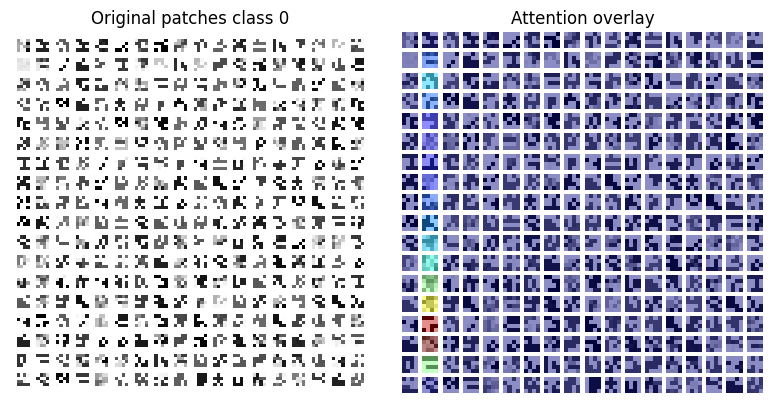

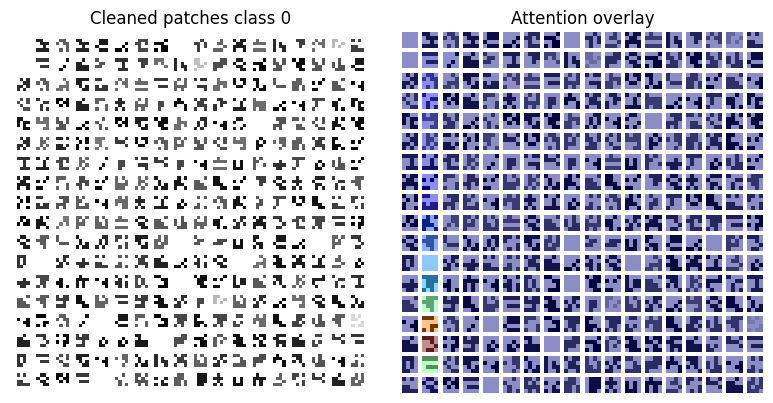

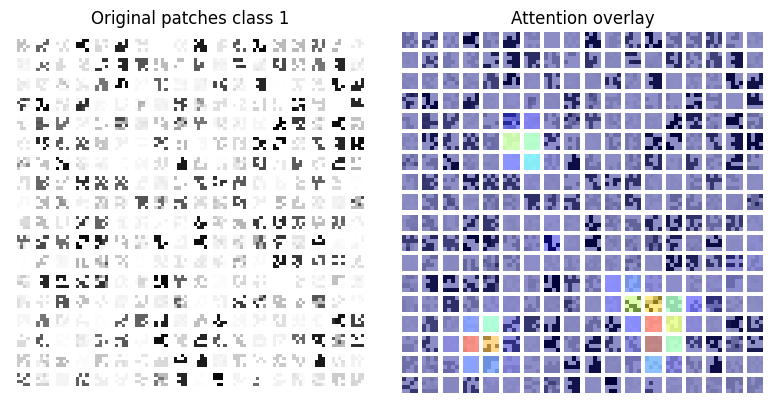

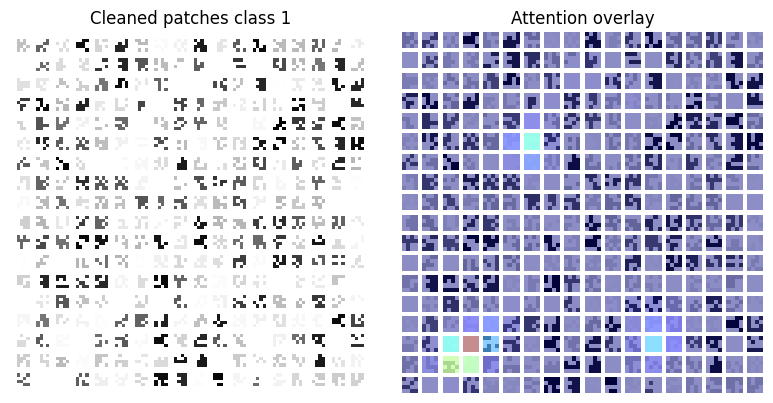

In [5]:
# we now can start analyzing the attention of a single sample:
# for a single label 0/1 example: 
class_0: int=int(torch.where(x_lab == 0)[0][0].item())
class_1: int=int(torch.where(x_lab == 1)[0][0].item())


show_attention(cnn_patches, attention_score, idx=class_0, figsize=(4,4), left_title="Original patches class 0") 
show_attention(cleaned_patches, attnpool_test_clean, idx=class_0, figsize=(4,4), left_title="Cleaned patches class 0") 

show_attention(cnn_patches, attention_score, idx=class_1, figsize=(4,4), left_title="Original patches class 1")
show_attention(cleaned_patches, attnpool_test_clean, idx=class_1, figsize=(4,4), left_title="Cleaned patches class 1")

Now let's dive into the results' analysis. Let's create a node graph to explore the patterns that show the highest attention score, and also look at what their neighbours are (top, bottom, left, right). For this I scaled the attention score per sample before averaging across the entire batch, which represent the node sizes. The bigger the size, the more attention that particular pattern had. Additionally, the neighbours (top, bottom, left, right) of each pattern were counted and added.

These two metrics will tell us the most important patterns that the CNN uses to define the class label, and which patterns the decoder matrix identified as important to place next to each other for the CNN's best performance. These will give us good candidate patterns that define the input tensor's class. Let's arbitrarily grab 1 000 samples, run them through the model, and stack the results together in a single batch so we can calculate the nodes and links.

In [6]:
device="cuda"
patterns_tensor=load_patterns_codebook().to("cuda")

stacked_patches:Tensor=torch.empty([])
stacked_attention:Tensor=torch.empty([])
stacked_labels:Tensor=torch.empty([])

# we iterate over many batches, then we concat the results into one tensor, for this example VRAM should be enough
# If not, the class is also desinged to add new nodes and links to the previous one and average them again

with torch.inference_mode(), torch.autocast(device_type='cuda', dtype=torch.bfloat16):
    for batch, loaded_data in enumerate(train_loader):
        X, label = loaded_data["image"], loaded_data["label"]
        X=X.to(device, non_blocking=True, memory_format=torch.channels_last)
        label=label.to(device, dtype=torch.float32, non_blocking=True)
            
        # 1st full inference
        cnn_patches_out = model_PSA(X,return_attention=True)[5]
        # Clean patterns
        cleaned_patches = Clean_patterns(cnn_patches=cnn_patches_out, pattern_book=patterns_tensor, input_tensor=X, threshold_ratio=0.7, binary_error_ratio=0.37).clean()
        # inference with only attnpool and the cleaned patches
        
        class_test_clean, attnpool_test_clean=model_PSA.attnpoolcnn(cleaned_patches.to("cuda")) # type: ignore        
        # Concat results together
        if batch ==0:
            stacked_patches     = cleaned_patches
            stacked_attention   = attnpool_test_clean
            stacked_labels      = label

        else :

            stacked_patches    = torch.cat((stacked_patches,cleaned_patches), dim=0)
            stacked_attention  = torch.cat((stacked_attention, attnpool_test_clean),  dim=0)
            stacked_labels     = torch.cat((stacked_labels, label),  dim=0)
                                    
        print(f"Batch: {batch+1}/{len(train_loader)}")


Batch: 1/167
Batch: 2/167
Batch: 3/167
Batch: 4/167
Batch: 5/167
Batch: 6/167
Batch: 7/167
Batch: 8/167
Batch: 9/167
Batch: 10/167
Batch: 11/167
Batch: 12/167
Batch: 13/167
Batch: 14/167
Batch: 15/167
Batch: 16/167
Batch: 17/167
Batch: 18/167
Batch: 19/167
Batch: 20/167
Batch: 21/167
Batch: 22/167
Batch: 23/167
Batch: 24/167
Batch: 25/167
Batch: 26/167
Batch: 27/167
Batch: 28/167
Batch: 29/167
Batch: 30/167
Batch: 31/167
Batch: 32/167
Batch: 33/167
Batch: 34/167
Batch: 35/167
Batch: 36/167
Batch: 37/167
Batch: 38/167
Batch: 39/167
Batch: 40/167
Batch: 41/167
Batch: 42/167
Batch: 43/167
Batch: 44/167
Batch: 45/167
Batch: 46/167
Batch: 47/167
Batch: 48/167
Batch: 49/167
Batch: 50/167
Batch: 51/167
Batch: 52/167
Batch: 53/167
Batch: 54/167
Batch: 55/167
Batch: 56/167
Batch: 57/167
Batch: 58/167
Batch: 59/167
Batch: 60/167
Batch: 61/167
Batch: 62/167
Batch: 63/167
Batch: 64/167
Batch: 65/167
Batch: 66/167
Batch: 67/167
Batch: 68/167
Batch: 69/167
Batch: 70/167
Batch: 71/167
Batch: 72/167
B

Now we can futher analyse the results. eg. we can visualize the most frequently occuring pattern that had the most attentionscroe and plot it.

In [7]:
nodesobj_class_0=Calculate_nodes_links(available_pattern=patterns_tensor, cnn_patch=stacked_patches[stacked_labels==0], attn=stacked_attention[stacked_labels==0])
nodesobj_class_1=Calculate_nodes_links(available_pattern=patterns_tensor, cnn_patch=stacked_patches[stacked_labels==1], attn=stacked_attention[stacked_labels==1])

nodes_links_class_0=nodesobj_class_0.get_nodes_and_links()
nodes_links_class_1=nodesobj_class_1.get_nodes_and_links()

graph_class_0 = Create_Network_Graph()
graph_class_0.build_pattern_graph(nodes=nodes_links_class_0[0],links=nodes_links_class_0[1], min_edge_weight=250, n_biggest_nodes=128)
# Note if total patches are less than 3 after filtering, plotting the execution will error (thus, adjust the min edges and number of nodes accordingly)
graph_class_0.style_and_plot(layout_name="circle", show_patterns=True, image_scale=1, always_show_annotation=False, title="Class 0 [X]")


graph_class_1 = Create_Network_Graph()
graph_class_1.build_pattern_graph(nodes=nodes_links_class_1[0],links=nodes_links_class_1[1], min_edge_weight=25, n_biggest_nodes=240)
graph_class_1.style_and_plot(layout_name="circle", show_patterns=True, image_scale=1, always_show_annotation=False, title="Class 1 [Diamond]")

Pattern with most average attention score for class 0


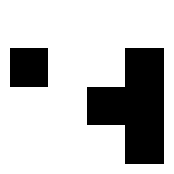

Pattern with most average attention score for class 1


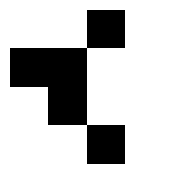

In [8]:
assert graph_class_0.graph_object is not None
assert graph_class_1.graph_object is not None

class_0_max = max(graph_class_0.graph_object.vs,key=lambda v: v["size"])["pattern"] # type: ignore
class_1_max = max(graph_class_1.graph_object.vs,key=lambda v: v["size"])["pattern"] # type: ignore
print("Pattern with most average attention score for class 0")
show_grid(torch.tensor(class_0_max).unsqueeze(0), figsize=(2,2))

print("Pattern with most average attention score for class 1")
show_grid(torch.tensor(class_1_max).unsqueeze(0), figsize=(2,2))

Now that the model has identified which patterns it considers most
informative for each class, let's check whether it recovered the
structure I embedded in the toy data.

As a reminder, the dataset generated by `synthetic_patterns` encodes a
specific permutation for each class:

- **Class 0** a specific permutation places specific patterns in form of a clear **X** shape.
- **Class 1** a specific permutation places specific patterns in form of a clear **Diamond** shape.

If the decoder has learned this mapping, the patterns with most mean attention should align with the true `X` / `Diamond` labels.

Let's sort the biggest 100 nodes from most attention to lowest and look up if they the model found patterns that we already knew were truly class defining. 

In [10]:
# Now let's load our pattern csv (with ground-truth labels) generated by the syntheticpatterns package when it initially created the dataset
all_patterns_df_=load_pattern_csv("./data/Pattern/All_patterns.csv")
# Get the pattern IDs and node sizes
assert graph_class_0.graph_object is not None
assert graph_class_1.graph_object is not None

class_0_pattern_ids = graph_class_0.graph_object.vs["pattern_id"]
class_1_pattern_ids = graph_class_1.graph_object.vs["pattern_id"]

class_0_sizes = graph_class_0.graph_object.vs["size"]
class_1_sizes = graph_class_1.graph_object.vs["size"]

# Let's subset the found pattern from our ground_truth IDs and add their sizes
class_0_results_df=all_patterns_df_.iloc[graph_class_0.graph_object.vs["pattern_id"]][["Name","Label"]].reset_index(drop=True) # type: ignore
class_1_results_df=all_patterns_df_.iloc[graph_class_1.graph_object.vs["pattern_id"]][["Name","Label"]].reset_index(drop=True) # type: ignore

class_0_results_df = (all_patterns_df_.iloc[class_0_pattern_ids][["Name", "Label"]].reset_index(drop=True))

class_0_results_df["Size_class_0"] = class_0_sizes

class_1_results_df = (all_patterns_df_.iloc[class_1_pattern_ids][["Name", "Label"]].reset_index(drop=True))

class_1_results_df["Size_class_1"] = class_1_sizes

# sort values by size
class_0_results_df=class_0_results_df.sort_values(
    by=["Size_class_0"],
    ascending=False,
    na_position="last"
    ).reset_index(drop=True)

class_1_results_df=class_1_results_df.sort_values(
    by=["Size_class_1"],
    ascending=False,
    na_position="last"
    ).reset_index(drop=True)




combined = pd.concat([
    class_0_results_df.rename(columns={
        "Name": "Pattern_ID_class_0",
        "Label": "Class 0 labels"
    }),
    class_1_results_df.rename(columns={
        "Name": "Pattern_ID_class_1",
        "Label": "Class 1 labels"
    })
    ], axis=1)


# Convert pattern IDs to integers
combined["Pattern_ID_class_0"] = combined["Pattern_ID_class_0"].astype("Int64")
combined["Pattern_ID_class_1"] = combined["Pattern_ID_class_1"].astype("Int64")

# Replace NaN labels with empty string
combined["Class 0 labels"] = combined["Class 0 labels"].fillna("")
combined["Class 1 labels"] = combined["Class 1 labels"].fillna("")

display(combined.style.hide(axis="index"))


Pattern_ID_class_0,Class 0 labels,Size_class_0,Pattern_ID_class_1,Class 1 labels,Size_class_1
368,['X'],0.048341,1494,['Diamond'],0.009687
4016,['X'],0.045866,2715,['Diamond'],0.008295
2213,['X'],0.043635,1768,['Diamond'],0.007284
2877,['X'],0.043159,1049,['Diamond'],0.006804
3828,['X'],0.042553,921,['Diamond'],0.006704
1116,['X'],0.040088,306,['Diamond'],0.006643
2864,"['X', 'Diamond']",0.039894,4014,['Diamond'],0.006625
2858,['X'],0.038762,1996,['Diamond'],0.006619
960,['X'],0.038590,1398,['Diamond'],0.006579
1678,['X'],0.037956,2065,['Diamond'],0.006559


>Note: Sometimes the model is biased towards correctly identifing patches of only one single class, and performs very bad on the other class. If this happens, my tests have shown, that using a different pretrained ViT weights and retraining the second phase may fix this. Using "good" vit weights often results in very good decoder and CNN predictions after training.

In [12]:
# Now let's calculate the correctly guessed patterns out of the total filtered:

valid_class0 = [["X"], ["X", "Diamond"]]
valid_class1 = [["Diamond"],["X", "Diamond"]]

total_patterns_filtered_class0=len(combined["Class 0 labels"].dropna()[combined["Class 0 labels"].dropna() != ""])
used_patterns_filtered_class0 = combined["Class 0 labels"][combined["Class 0 labels"].dropna() != ""].apply(lambda x: x in valid_class0).sum()

total_patterns_filtered_class1=len(combined["Class 1 labels"].dropna()[combined["Class 1 labels"].dropna() != ""])
used_patterns_filtered_class1 = combined["Class 1 labels"][combined["Class 1 labels"].dropna() != ""].apply(lambda x: x in valid_class1).sum()

# get rid of empty rows before averaging
pct_exact_class0 = (combined["Class 0 labels"][combined["Class 0 labels"].dropna() != ""].apply(lambda x: x in valid_class0)).mean() * 100
pct_exact_class1 = (combined["Class 1 labels"][combined["Class 1 labels"].dropna() != ""].apply(lambda x: x in valid_class1)).mean() * 100


# Let's do some statistics:
# A hypergeometric enrichment test: is the number of correctly-identified patterns among the top ones with most average attention higher than what random chance would produce?
# What's the chance of getting this many patterns right? What's expected by random? What is the enrichment?

# Total number of unique patterns
N = 4096

# Ground-truth number of valid patterns
K0 = all_patterns_df_["Label"].apply(lambda x: x in [["X"], ["X", "Diamond"]]).sum() # =128
K1 = all_patterns_df_["Label"].apply(lambda x: x in [["Diamond"], ["X", "Diamond"]]).sum() # =240

# Number of top patterns considered
n0 = total_patterns_filtered_class0 
n1 = total_patterns_filtered_class1

# Number of correctly identified patterns
observed0 = used_patterns_filtered_class0
observed1 = used_patterns_filtered_class1

# Percentages relative to ALL 4096 possible patterns
chance_pct_class0 = K0 / N * 100
chance_pct_class1 = K1 / N * 100

# Observed percentages among the top patterns
pct_class0 = observed0 / n0 * 100
pct_class1 = observed1 / n1 * 100

# Hypergeometric p-values
p0 = hypergeom.sf(observed0 - 1, N, K0, n0)
p1 = hypergeom.sf(observed1 - 1, N, K1, n1)

print("Class 0")
print(f"Ground-truth patterns:            {K0}/{N} ({chance_pct_class0:.2f}% of all patterns)")
print(f"Random expected for 128 patterns: {n0 * K0 / N:.2f}/{n0} ({chance_pct_class0:.2f}%)")
print(f"Correctly identified:             {observed0}/{n0} ({pct_class0:.1f}%)")
print(f"Enrichment:                       {pct_class0 / chance_pct_class0:.1f}x")
print(f"p-value:                          {p0:.3e}")

print("-------")

print("Class 1")
print(f"Ground-truth patterns:            {K1}/{N} ({chance_pct_class1:.2f}% of all patterns)")
print(f"Random expected for 240 patterns: {n1 * K1 / N:.2f}/{n1} ({chance_pct_class1:.2f}%)")
print(f"Correctly identified:             {observed1}/{n1} ({pct_class1:.1f}%)")
print(f"Enrichment:                       {pct_class1 / chance_pct_class1:.1f}x")
print(f"p-value:                          {p1:.3e}")


Class 0
Ground-truth patterns:            128/4096 (3.12% of all patterns)
Random expected for 128 patterns: 4.00/128 (3.12%)
Correctly identified:             128/128 (100.0%)
Enrichment:                       32.0x
p-value:                          1.188e-246
-------
Class 1
Ground-truth patterns:            240/4096 (5.86% of all patterns)
Random expected for 240 patterns: 14.06/240 (5.86%)
Correctly identified:             212/240 (88.3%)
Enrichment:                       15.1x
p-value:                          1.203e-288


Out of the 128/240 candidate patterns with the highest average attention, the model correctly identified all 128 correct class0 patterns and 212 class1 patterns. This corresponds to an enrichments of 32x and 15.1x over random chance (with a p < 1e-246).

A top scoring pattern not labelled inside the known ground truth list is not necessarily a false positive. Only a subset of all patterns were explicitly designated as class defining during data generation, therefore other high attention "unlabeled" patterns may still carry real class discriminative structure.

Taken together, these results show the model does more than classify samples correctly, its learned attention is strongly and measurably aligned with the actual class defining patterns in this controlled synthetic setting, suggesting that this architecture is a promising candidate for problems where explicit ground truth is limited or unavailable.